In [24]:
import pandas as pd
import numpy as np
from statsbombpy import sb
from itertools import groupby
import matplotlib.pyplot as plt

In [25]:
df = pd.read_csv("football_matches_odds.csv")
df = df.tail(1500)
conditions = [
    (df["odds_home_win"] <= df["odds_draw"]) & (df["odds_home_win"] <= df["odds_away_win"]),
    (df["odds_away_win"] <= df["odds_draw"]) & (df["odds_home_win"] >= df["odds_away_win"]),
    (df["odds_away_win"] >= df["odds_draw"]) & (df["odds_home_win"] >= df["odds_draw"])
]

values = ["home", "away", "draw"]

df["pred"] = np.select(conditions, values, default=None)

In [26]:
inv_home = 1 / df["odds_home_win"]
inv_draw = 1 / df["odds_draw"]
inv_away = 1 / df["odds_away_win"]
total = inv_home + inv_draw + inv_away

df["prob_home"] = inv_home / total
df["prob_draw"] = inv_draw / total
df["prob_away"] = inv_away / total
df

,match_id,date,time,league,season,home_team,away_team,home_goals,away_goals,winner,...,odds_away_win,odds_source,market_avg_home_win,market_avg_draw,market_avg_away_win,division,pred,prob_home,prob_draw,prob_away
7408,7409,2025-09-27,20:00,Premier League,2025-26,Tottenham,Wolves,1,1,draw,...,6.00,b365,1.47,4.57,6.38,E0,home,0.631579,0.210526,0.157895
7409,7410,2025-09-27,14:00,Serie A,2025-26,Como,Cremonese,1,1,draw,...,8.00,b365,1.44,4.41,7.45,I1,home,0.659577,0.220875,0.119548
7410,7411,2025-09-27,17:00,Serie A,2025-26,Juventus,Atalanta,1,1,draw,...,4.20,b365,1.86,3.55,4.16,I1,home,0.511675,0.262944,0.225381
7411,7412,2025-09-27,19:45,Serie A,2025-26,Cagliari,Inter,0,2,away,...,1.53,b365,5.85,4.16,1.54,I1,away,0.157477,0.224967,0.617556
7412,7413,2025-09-28,14:30,Bundesliga,2025-26,Freiburg,Hoffenheim,1,1,draw,...,3.10,b365,2.19,3.59,3.01,D1,home,0.418836,0.277171,0.303994
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8903,8904,2026-05-24,19:45,Serie A,2025-26,Cremonese,Como,1,4,away,...,1.57,b365,5.33,4.05,1.55,I1,away,0.179972,0.218211,0.601817
8904,8905,2026-05-24,19:45,Serie A,2025-26,Lecce,Genoa,1,0,home,...,5.00,b365,1.73,3.42,4.84,I1,home,0.540541,0.270270,0.189189
8905,8906,2026-05-24,19:45,Serie A,2025-26,Milan,Cagliari,1,2,away,...,11.00,b365,1.26,5.30,10.35,I1,home,0.739744,0.173504,0.086752
8906,8907,2026-05-24,19:45,Serie A,2025-26,Torino,Juventus,2,2,draw,...,1.42,b365,7.23,4.45,1.40,I1,away,0.125812,0.209687,0.664501


In [27]:
df["guessed_correct"] = df["pred"] == df["winner"]

In [28]:
print(f"Total correct guesses: {df["guessed_correct"].sum()} out of {len(df)}")

leagues = {
    "SP1": "La Liga",
    "E0": "Premier League",
    "D1": "Bundesliga",
    "I1": "Serie A",
    "F1": "Ligue 1"
}

for code, name in leagues.items():
    league_df = df[df["league"] == name]
    accuracy = league_df["guessed_correct"].mean() * 100

    print(f"{name} accuracy: {accuracy:.2f}%")



Total correct guesses: 799 out of 1500
La Liga accuracy: 55.56%
Premier League accuracy: 49.69%
Bundesliga accuracy: 54.92%
Serie A accuracy: 53.24%
Ligue 1 accuracy: 53.31%


In [29]:
streaks = {
    value: max(
        (len(list(group)) for k, group in groupby(df["guessed_correct"]) if k == value),
        default=0
    )
    for value in [True, False]
}

print(f"Max consecutive correct: {streaks[True]}")
print(f"Max consecutive incorrect: {streaks[False]}")

Max consecutive correct: 11
Max consecutive incorrect: 11


## Betting simulator with confidence threshold

`confidence` is the normalized implied probability of the pick (`max(prob_home, prob_draw, prob_away)`). Only matches with confidence at or above the threshold are bet. Each selected match stakes `BET_PERCENTAGE` of the current bankroll, so stakes compound.

Change `LEAGUE`, `CONFIDENCE_THRESHOLD`, or the threshold list to explore. A threshold of `0.0` means no filter.


=== Final bankroll ===


,0.5%,1.0%,2.0%,3.0%,5.0%,10.0%
threshold,,,,,,
0.00,108.96,117.77,134.38,148.57,165.25,124.69
0.40,98.92,97.38,93.02,87.16,72.20,31.99
0.45,100.01,99.74,98.37,95.90,88.07,57.96
0.50,101.01,101.86,103.07,103.58,102.48,88.26
0.55,104.99,110.12,120.82,132.06,155.98,220.95
0.60,101.59,103.16,106.22,109.14,114.55,124.65
0.65,101.45,102.89,105.76,108.59,114.13,126.82
0.70,101.99,104.01,108.14,112.37,121.15,144.93
0.75,101.79,103.61,107.34,111.20,119.31,142.10



=== ROI on starting capital (%) ===


,0.5%,1.0%,2.0%,3.0%,5.0%,10.0%
threshold,,,,,,
0.00,8.96,17.77,34.38,48.57,65.25,24.69
0.40,-1.08,-2.62,-6.98,-12.84,-27.80,-68.01
0.45,0.01,-0.26,-1.63,-4.10,-11.93,-42.04
0.50,1.01,1.86,3.07,3.58,2.48,-11.74
0.55,4.99,10.12,20.82,32.06,55.98,120.95
0.60,1.59,3.16,6.22,9.14,14.55,24.65
0.65,1.45,2.89,5.76,8.59,14.13,26.82
0.70,1.99,4.01,8.14,12.37,21.15,44.93
0.75,1.79,3.61,7.34,11.20,19.31,42.10



=== Yield on turnover (%) ===


,0.5%,1.0%,2.0%,3.0%,5.0%,10.0%
threshold,,,,,,
0.00,5.35,5.01,4.35,3.73,2.61,0.43
0.40,-0.90,-1.10,-1.49,-1.87,-2.59,-4.18
0.45,0.02,-0.15,-0.49,-0.84,-1.57,-3.60
0.50,1.59,1.45,1.19,0.92,0.39,-0.98
0.55,10.76,10.71,10.62,10.52,10.31,9.68
0.60,5.20,5.14,5.02,4.89,4.62,3.88
0.65,6.69,6.63,6.52,6.40,6.16,5.55
0.70,12.32,12.27,12.17,12.07,11.86,11.33
0.75,19.72,19.73,19.73,19.74,19.75,19.77


... (2 outputs left out)


=== Number of bets ===


,0.5%,1.0%,2.0%,3.0%,5.0%,10.0%
threshold,,,,,,
0.00,315,315,315,315,315,315
0.40,239,239,239,239,239,239
0.45,173,173,173,173,173,173
0.50,127,127,127,127,127,127
0.55,91,91,91,91,91,91
0.60,61,61,61,61,61,61
0.65,43,43,43,43,43,43
0.70,32,32,32,32,32,32
0.75,18,18,18,18,18,18



=== Per-threshold summary (independent of bet size) ===


,bets,accuracy_%,avg_confidence,avg_odds
threshold,,,,
0.00,315,55.6,0.499,2.00
0.40,239,57.3,0.539,1.83
0.45,173,62.4,0.582,1.68
0.50,127,67.7,0.622,1.55
0.55,91,76.9,0.659,1.46
0.60,61,78.7,0.704,1.36
0.65,43,83.7,0.738,1.29
0.70,32,90.6,0.762,1.25
0.75,18,100.0,0.793,1.20


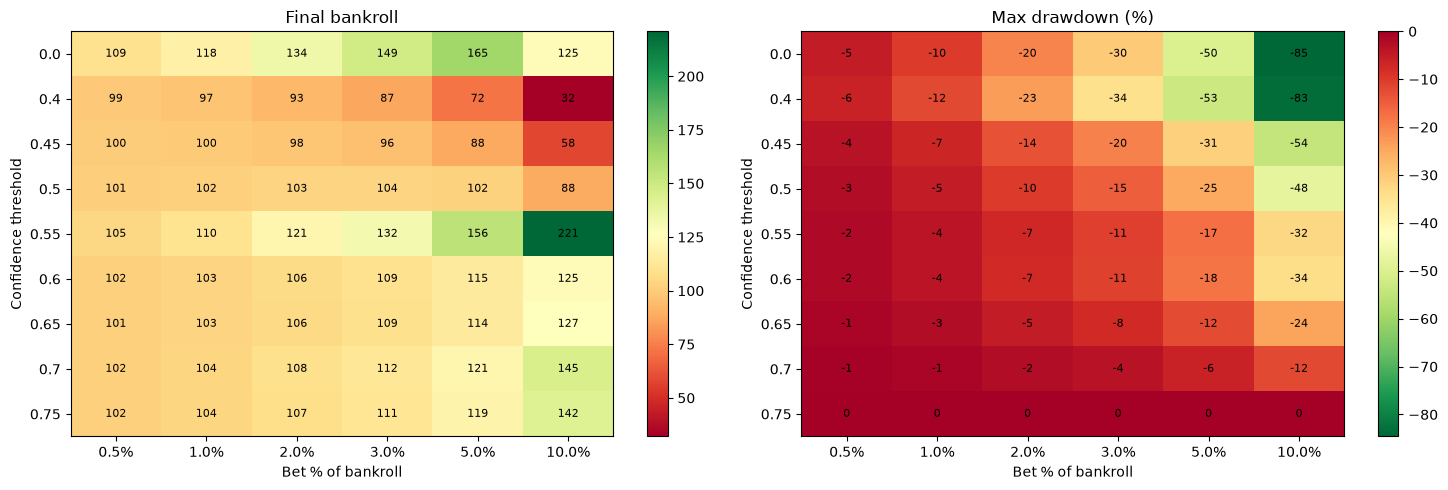

In [32]:
LEAGUE = "La Liga"          # set to None to include every league
STARTING_CAPITAL = 100.0
BET_PERCENTAGE = 0.1
CONFIDENCE_THRESHOLD = 0.65


def simulate(threshold, league=LEAGUE, starting_capital=STARTING_CAPITAL,
             bet_percentage=BET_PERCENTAGE):
    """Bet a fixed share of the current bankroll only above a confidence threshold."""
    sim = df.copy()
    if league is not None:
        sim = sim[sim["league"] == league]
    sim = sim.sort_values(["date", "match_id"]).reset_index(drop=True)

    sim["odds_taken"] = np.select(
        [sim["pred"] == "home", sim["pred"] == "draw", sim["pred"] == "away"],
        [sim["odds_home_win"], sim["odds_draw"], sim["odds_away_win"]],
        default=np.nan,
    )
    sim["confidence"] = sim[["prob_home", "prob_draw", "prob_away"]].max(axis=1)
    sim = sim[
        (sim["confidence"] >= threshold)
        & sim["odds_taken"].notna()
        & (sim["odds_taken"] > 1)
    ].reset_index(drop=True)

    bankroll = starting_capital
    history = []
    for match in sim.itertuples(index=False):
        stake = bankroll * bet_percentage
        profit = stake * (match.odds_taken - 1) if match.guessed_correct else -stake
        bankroll += profit
        history.append({
            "match_id": match.match_id,
            "date": match.date,
            "confidence": match.confidence,
            "odds": match.odds_taken,
            "won": match.guessed_correct,
            "stake": stake,
            "profit": profit,
            "bankroll": bankroll,
        })

    history = pd.DataFrame(history)
    if history.empty:
        return {
            "threshold": threshold, "bet_percentage": bet_percentage, "bets": 0,
            "accuracy": np.nan, "avg_confidence": np.nan, "avg_odds": np.nan,
            "final_bankroll": starting_capital, "net_profit": 0.0,
            "total_staked": 0.0, "roi_pct": np.nan, "yield_pct": np.nan,
            "max_drawdown_pct": 0.0,
        }, history

    peak = history["bankroll"].cummax()
    drawdown = (history["bankroll"] - peak) / peak
    net_profit = bankroll - starting_capital
    total_staked = history["stake"].sum()
    return {
        "threshold": threshold,
        "bet_percentage": bet_percentage,
        "bets": len(history),
        "accuracy": float(history["won"].mean()),
        "avg_confidence": float(history["confidence"].mean()),
        "avg_odds": float(history["odds"].mean()),
        "final_bankroll": float(bankroll),
        "net_profit": float(net_profit),
        "total_staked": float(total_staked),
        "roi_pct": float(net_profit / starting_capital * 100),
        "yield_pct": float(net_profit / total_staked * 100),
        "max_drawdown_pct": float(drawdown.min() * 100),
    }, history


# ---------- Grid: thresholds x bet percentages ----------
thresholds = [0.0, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75]
bet_percentages = [0.005, 0.01, 0.02, 0.03, 0.05, 0.10]

grid = pd.DataFrame([
    simulate(t, bet_percentage=b)[0]
    for t in thresholds
    for b in bet_percentages
])


def pivot(metric, decimals=2):
    p = grid.pivot(index="threshold", columns="bet_percentage", values=metric).round(decimals)
    p.columns = [f"{c:.1%}" for c in p.columns]
    return p


tables = {
    "Final bankroll": pivot("final_bankroll"),
    "ROI on starting capital (%)": pivot("roi_pct"),
    "Yield on turnover (%)": pivot("yield_pct"),
    "Max drawdown (%)": pivot("max_drawdown_pct", 1),
    "Number of bets": pivot("bets", 0),
}
for title, table in tables.items():
    print(f"\n=== {title} ===")
    display(table)

# Bets, accuracy and odds do not depend on bet size, so show them once
print("\n=== Per-threshold summary (independent of bet size) ===")
summary = (grid[grid["bet_percentage"] == BET_PERCENTAGE]
           [["threshold", "bets", "accuracy", "avg_confidence", "avg_odds"]]
           .assign(accuracy=lambda d: (d["accuracy"] * 100).round(1))
           .round({"avg_confidence": 3, "avg_odds": 2})
           .rename(columns={"accuracy": "accuracy_%"})
           .set_index("threshold"))
display(summary)

# ---------- Heatmaps ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (title, table) in zip(axes, [("Final bankroll", tables["Final bankroll"]),
                                     ("Max drawdown (%)", tables["Max drawdown (%)"])]):
    cmap = "RdYlGn" if "bankroll" in title else "RdYlGn_r"
    im = ax.imshow(table.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.set_xlabel("Bet % of bankroll")
    ax.set_ylabel("Confidence threshold")
    ax.set_title(title)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f"{table.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

*Best configs (La Liga only):*
- 0.65, 0.1 (135% profit, 44% DD)
Expect around 26% profit and 24% DD per season
- 0.65, 0.05 (71.3% profit, 24% DD)
- 0.65, 0.03 (41.8% profit, 15% DD)
- 0.65, 0.02 (27.3% profit, 10% DD)
- 0.65, 0.01 (13.3% profit, 5% DD)

### Run one threshold

League: La Liga
Confidence threshold: 65%
Matches bet: 43
Accuracy: 83.7%
Average confidence: 73.8%
Average odds: 1.29
Final bankroll: 126.82
Net profit: +26.82
Return on turnover: +26.82%
Max drawdown: -24.2%


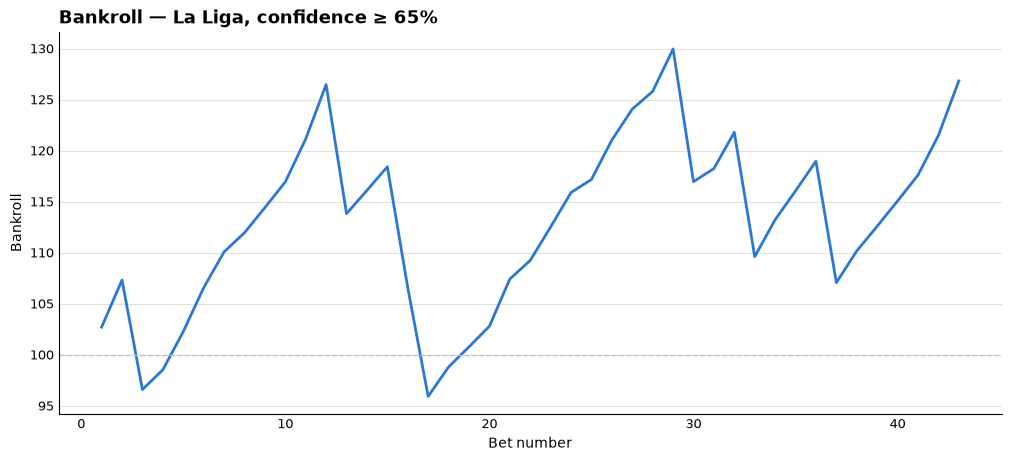

In [33]:
import matplotlib.pyplot as plt

metrics, history = simulate(CONFIDENCE_THRESHOLD)

print(f"League: {LEAGUE or 'all leagues'}")
print(f"Confidence threshold: {CONFIDENCE_THRESHOLD:.0%}")
print(f"Matches bet: {metrics['bets']:,}")
print(f"Accuracy: {metrics['accuracy']:.1%}")
print(f"Average confidence: {metrics['avg_confidence']:.1%}")
print(f"Average odds: {metrics['avg_odds']:.2f}")
print(f"Final bankroll: {metrics['final_bankroll']:,.2f}")
print(f"Net profit: {metrics['net_profit']:+,.2f}")
print(f"Return on turnover: {metrics['roi_pct']:+.2f}%")
print(f"Max drawdown: {metrics['max_drawdown_pct']:.1f}%")

if history.empty:
    print("No matches meet the threshold.")
else:
    fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
    ax.plot(np.arange(1, len(history) + 1), history["bankroll"],
            color="#2a78d6", linewidth=2)
    ax.axhline(STARTING_CAPITAL, color="#c3c2b7", linewidth=1, linestyle="--")
    ax.set_title(
        f"Bankroll — {LEAGUE or 'all leagues'}, confidence ≥ {CONFIDENCE_THRESHOLD:.0%}",
        loc="left", fontsize=13, fontweight="bold",
    )
    ax.set_xlabel("Bet number")
    ax.set_ylabel("Bankroll")
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=9, length=0)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    plt.show()